# 01 – Exploration des données

**Objectif** : comprendre les données avant toute modélisation.
- Quelles colonnes reçoit-on ? Quel format ? Y a-t-il des valeurs manquantes ?
- Combien de matchs du PSG avons-nous ?
- À quoi ressemble notre cible (victoire / pas victoire) ? Est-elle équilibrée ?

> Prérequis : avoir lancé `python -m src.data_ingestion` depuis la racine du projet.

In [19]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from src import config
from src.data_loading import load_raw

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",60)

## 1. Chargement des données brutes

In [5]:
raw=load_raw()
print(raw.shape)
raw.head()

(1008, 177)


c:\Users\angel\Codage\Build_Project\Psg-ML\ML_prono\notebooks\..\src\data_loading.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Season"] = season
c:\Users\angel\Codage\Build_Project\Psg-ML\ML_prono\notebooks\..\src\data_loading.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Season"] = season
c:\Users\angel\Codage\Build_Project\Psg-ML\ML_prono\notebooks\..\src\data_loading.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,IWH,...,LBA,BFDCH,BFDCD,BFDCA,BMGMCH,BMGMCD,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA,HxG,AxG,PPH,PPD,PPA,SKBH,SKBD,SKBA,PPCH,PPCD,PPCA,SKBCH,SKBCD,SKBCA
0,F1,11/08/2023,20:00,Nice,Lille,1,1,D,1,0,H,8,12,3,5,13,9,3,3,3,2,0,0,2.60,3.5,2.70,2.60,3.4,2.65,2.55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,12/08/2023,16:00,Marseille,Reims,2,1,H,1,1,D,14,11,4,4,7,16,10,10,1,3,0,0,1.70,4.0,4.75,1.65,4.1,4.80,1.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F1,12/08/2023,20:00,Paris SG,Lorient,0,0,D,0,0,D,20,4,4,0,8,6,9,2,0,0,0,0,1.33,5.5,7.50,1.32,5.5,9.00,1.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F1,13/08/2023,12:00,Brest,Lens,3,2,H,1,2,A,15,10,8,2,13,15,6,8,2,3,0,1,4.00,3.5,1.91,3.90,3.5,1.93,3.90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,F1,13/08/2023,14:00,Clermont,Monaco,2,4,A,1,2,A,15,14,7,8,7,16,6,2,0,4,0,0,3.60,3.6,2.00,3.50,3.7,2.00,3.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Analyse des données brutes

1. Beaucoup de valeur NaN, on va surement toutes les drop

2. On va devoir numériser les valeurs hometeam et awayteam afin de les utiliser pour
 le calcul de la fonction linéaire
 
3. On a beaucoup trop de features il va falloir faire un tri afin de garder un model simple et efficace

## 2. Structure du jeu de données

In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Columns: 177 entries, Div to SKBCA
dtypes: float64(152), int64(16), str(9)
memory usage: 1.4 MB


### Colonnes principales (documentation football-data.co.uk)

| Colonne | Signification |
|---|---|
| `Date` | Date du match (format jj/mm/aaaa, parfois jj/mm/aa) |
| `HomeTeam` / `AwayTeam` | Équipe à domicile / à l'extérieur |
| `FTHG` / `FTAG` | Buts à domicile / à l'extérieur à la fin du match (*Full Time*) |
| `FTR` | Résultat final : `H` (domicile), `D` (nul), `A` (extérieur) |
| `HTHG` / `HTAG` / `HTR` | Même chose à la mi-temps (*Half Time*) |
| `HS`, `AS`, `HST`, `AST`... | Tirs, tirs cadrés, fautes, corners, cartons |
| `B365H`, `B365D`, `B365A`... | Cotes de bookmakers (domicile / nul / extérieur) |
| `Season` | Ajoutée par nous : saison du fichier d'origine |

⚠️ Les colonnes de stats du match (tirs, corners, cotes de clôture...) ne sont connues
qu'**après** le match (ou juste avant pour les cotes). On ne pourra les utiliser dans le
modèle qu'à travers leur historique passé, sinon on triche (*data leakage*).

## 3. Dates et valeurs manquantes


In [7]:
df=raw.copy()
df["Date"]=pd.to_datetime(df["Date"],dayfirst=True,format="mixed")
print("Période couverte :", df["Date"].min().date(), "→", df["Date"].max().date())

Période couverte : 2023-08-11 → 2026-11-08


In [8]:
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing[missing > 0].round(1).head(20)

PPH      91.1
SKBCD    91.1
SKBCA    91.1
PPCA     91.1
SKBCH    91.1
PPA      91.1
SKBH     91.1
AxG      91.1
HxG      91.1
SKBA     91.1
SKBD     91.1
PPCH     91.1
PPCD     91.1
PPD      91.1
IWD      84.8
IWH      84.8
IWA      84.8
IWCH     84.8
IWCA     84.8
IWCD     84.8
dtype: float64

On remarque donc aucune valeur importante manquante et la période couverte correspond à nos attentes

## 4. Matchs et équipes par saison

In [9]:
summary = df.groupby("Season").agg(
    nb_matchs=("Date", "size"),
    nb_equipes=("HomeTeam", "nunique"),
)
summary

,nb_matchs,nb_equipes
Season,,
2324,306,18
2425,306,18
2526,306,18
2627,90,18


## 5. Création de la cible

FTR
H    446
A    324
D    238
Name: count, dtype: int64

Taux de victoire à domicile : 44.2%


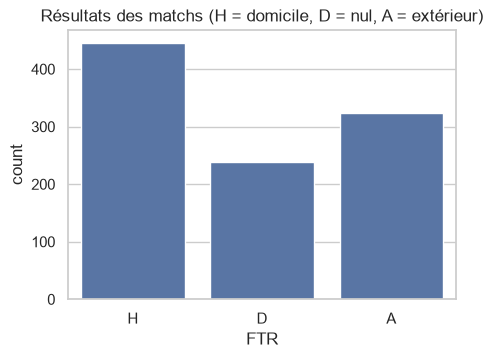

In [10]:
df["home_win"] = (df["FTR"] == "H").astype(int)  # <-- notre cible

print(df["FTR"].value_counts())
print(f"\nTaux de victoire à domicile : {df['home_win'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="FTR", order=["H", "D", "A"], ax=ax)
ax.set_title("Résultats des matchs (H = domicile, D = nul, A = extérieur)")
plt.show()

**Lecture** : la classe « victoire à domicile » (1) représente un peu moins de la moitié des matchs.
Un modèle stupide qui prédit *toujours* « pas de victoire à domicile » aura donc déjà
environ 56 % d'accuracy : c'est notre **baseline** à battre.

## 6. L'avantage du terrain,saison par saison

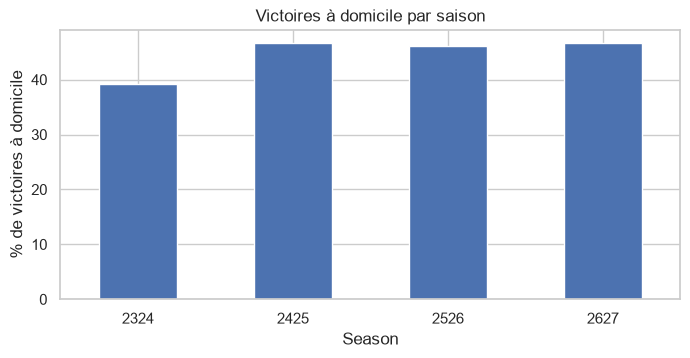

In [11]:
home_adv = df.groupby("Season")["home_win"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
home_adv.plot(kind="bar", ax=ax)
ax.set_ylabel("% de victoires à domicile")
ax.set_title("Victoires à domicile par saison")
plt.xticks(rotation=0)
plt.show()

## 7. Les équipes : taux de victoire (tous matchs confondus)

In [17]:
home = df.assign(team=df["HomeTeam"], win=(df["FTR"] == "H"))
away = df.assign(team=df["AwayTeam"], win=(df["FTR"] == "A"))
long = pd.concat([home[["team", "Season", "win"]], away[["team", "Season", "win"]]])

team_stats = long.groupby("team").agg(
    taux_victoire=("win", "mean"),
    nb_matchs=("win", "size"),
    nb_saisons=("Season", "nunique"),
).sort_values("taux_victoire", ascending=False)
team_stats["taux_victoire"] = (team_stats["taux_victoire"] * 100).round(1)

team_stats.head(10)

,taux_victoire,nb_matchs,nb_saisons
team,,,
Paris SG,70.5,112,4
Monaco,51.8,112,4
Lille,50.9,112,4
Marseille,50.9,112,4
Lyon,50.0,112,4
Lens,49.1,112,4
Rennes,42.0,112,4
Brest,41.1,112,4
Nice,39.3,112,4


## 8. Contrôles qualité

In [20]:
print("Doublons               :", df.duplicated(subset=["Date", "HomeTeam", "AwayTeam"]).sum())
print("Scores manquants       :", df[["FTHG", "FTAG"]].isna().sum().sum())
print("Résultat (FTR) manquant:", df["FTR"].isna().sum())

# Cohérence entre FTR et le score
expected = np.where(df["FTHG"] > df["FTAG"], "H", np.where(df["FTHG"] == df["FTAG"], "D", "A"))
print("FTR incohérent avec le score :", (df["FTR"] != expected).sum())

Doublons               : 0
Scores manquants       : 0
Résultat (FTR) manquant: 0
FTR incohérent avec le score : 0


In [22]:
# Statistiques descriptives des colonnes numériques principales
cols = ["FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "HST", "AST"]
raw[cols].describe().round(2)

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST
count,1008.00,1008.00,1008.00,1008.00,1008.00,1008.00,1008.00,1008.00
mean,1.55,1.29,0.67,0.57,13.75,11.40,4.92,4.14
std,1.29,1.22,0.81,0.78,5.25,4.81,2.51,2.43
min,0.00,0.00,0.00,0.00,2.00,1.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,10.00,8.00,3.00,2.00
50%,1.00,1.00,1.00,0.00,13.00,11.00,5.00,4.00
75%,2.00,2.00,1.00,1.00,17.00,14.00,6.00,6.00
max,8.00,7.00,6.00,4.00,41.00,31.00,14.00,13.00


## 9. Conclusions 

- **Taille du dataset** : 1008 matchs.
- **Baseline à battre** : 55% (accuracy en prédisant toujours « pas de victoire à domicile »).
- **Qualité** : Parfaite (valeurs manquantes, doublons, incohérences).
- **Piège principal** : ne jamais utiliser d'information postérieure au match à prédire.